In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp

# 基础内容
## 优化器

In [3]:
#非线性方程数值求根求根
#x+cos(x)
#寻找使函数值等于0的未知数
from scipy.optimize import root

def eqn(x):
    return x + np.cos(x)

myroot = root(eqn,0)
#对函数eqn求根  从初始猜测值0开始寻找
print(myroot.x)
print(myroot)

[-0.73908513]
 message: The solution converged.
 success: True
  status: 1
     fun: [ 0.000e+00]
       x: [-7.391e-01]
  method: hybr
    nfev: 11
    fjac: [[-1.000e+00]]
       r: [-1.674e+00]
     qtf: [-2.668e-13]


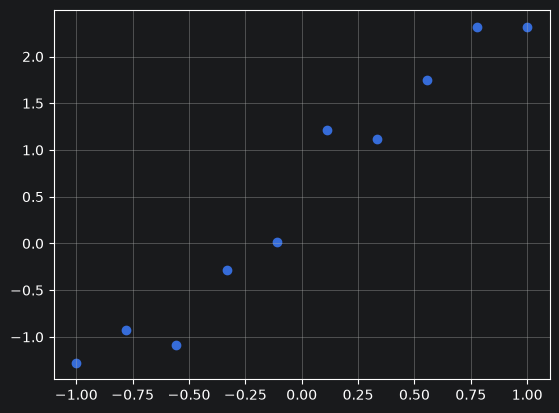

In [17]:
#最小二乘法拟合(leastsq)
import numpy as np
from scipy.optimize import leastsq

x = np.linspace(-1,1,10)
y = x*2+np.random.random(10)

import matplotlib.pyplot as plt
plt.scatter(x,y)
plt.grid(True)
plt.show()

In [24]:
#y= kx+b
#输入参数，返回的是真实值和预测值之间的差值
def residuals(p):
    k,b = p
    return y-(k*x+b)

r = leastsq(residuals,[1,0])
k,b = r[0]
print(k,b)

2.0335588246385843 0.5164114947829365


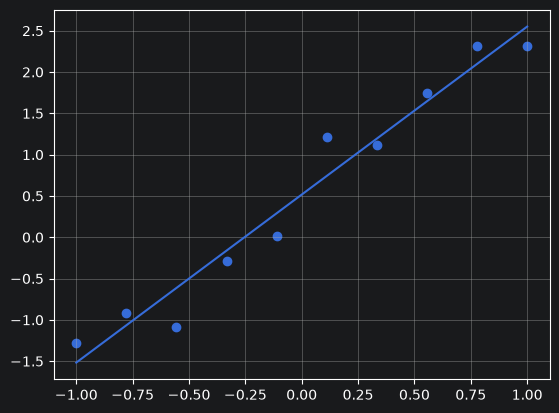

In [26]:
y1 =k*x+b

plt.scatter(x,y)
plt.plot(x,y1)
plt.grid(True)
plt.show()

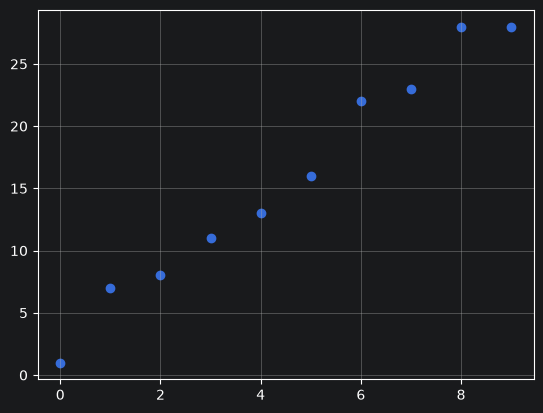

In [29]:
#最小二乘法实验
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(10)
y = x*3+np.random.randint(1,5,size=10)

plt.scatter(x,y)
plt.grid(True)
plt.show()

In [33]:
x_mean = np.mean(x)
y_mean = np.mean(y)

k = np.sum((x-x_mean)*(y-y_mean))/np.sum((x-x_mean)*(x-x_mean))
b = y_mean-k*x_mean
print(k,b)

3.036363636363636 2.036363636363637


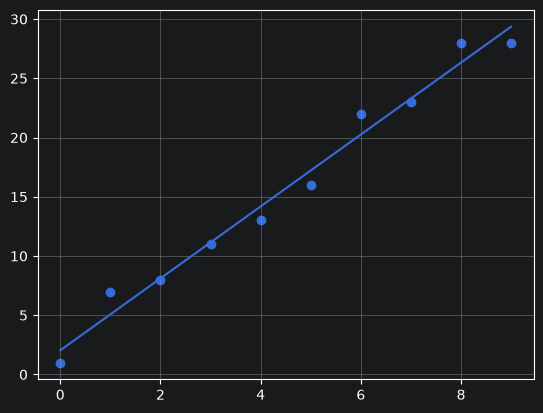

In [35]:
y1 =k*x+b

plt.scatter(x,y)
plt.plot(x,y1)
plt.grid(True)
plt.show()

In [37]:
#封装函数
def leastsq(x,y):
    x_mean = np.mean(x)
    y_mean = np.mean(y)

    k = np.sum((x-x_mean)*(y-y_mean))/np.sum((x-x_mean)*(x-x_mean))
    b = y_mean-k*x_mean
    return{'k':k,'b':b}

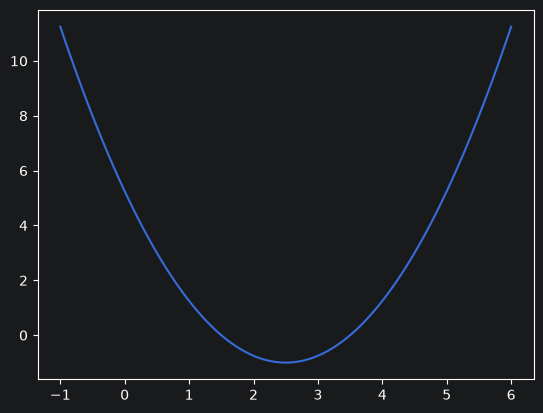

In [39]:
#梯度下降算法
x = np.linspace(-1,6,100)
y = (x-2.5)**2-1

plt.plot(x,y)
plt.show()

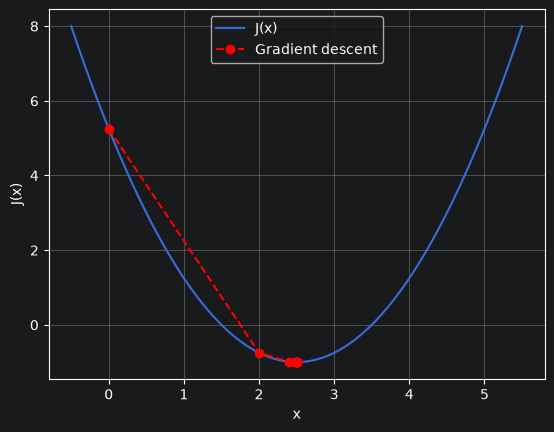

In [46]:
def J(x):
    return (x-2.5)**2-1
def gradient(x):
    return 2 * (x - 2.5)

x = 0.0
eta = 0.4 #学习率：控制每次更新的幅度
x_history = [x]

for i in range(1000):
    dJ = gradient(x)
    if abs(dJ) < 1e-6:
        break

    x = x - eta * dJ
    x_history.append(x)
xs = np.linspace(-0.5, 5.5, 400)
plt.plot(xs, J(xs), label='J(x)')

plt.plot(
    x_history,
    [J(value) for value in x_history],
    'ro--',
    label='Gradient descent'
)

plt.xlabel('x')
plt.ylabel('J(x)')
plt.legend()
plt.grid(True)
plt.show()

In [1]:
#最小化函数
from scipy.optimize import minimize

def eqn(x):
    return x**2 + x +2

mymin = minimize(eqn,0,method ='BFGS')
print(mymin.x)
print(mymin)

[-0.50000001]
  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 1.75
        x: [-5.000e-01]
      nit: 2
      jac: [ 0.000e+00]
 hess_inv: [[ 5.000e-01]]
     nfev: 8
     njev: 4


In [15]:
import scipy.optimize as opt
import numpy as np

In [16]:
#Rosenbrock函数
def f(p):
    x,y = p
    z = (1-x)**2+100*(y-x**2)**2
    return z

result = opt.fmin(f,[2,2]) #fmin()默认直接返回坐标数组
print(result)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 62
         Function evaluations: 119
[0.99998292 0.99996512]


In [17]:
#梯度函数
def fprime(p):
    x,y =p
    dx = -2+2*x-400*x*(y-x**2)
    dy = 200*y-200*x**2
    return np.array([dx,dy])

In [12]:
#Nelder–Mead 无梯度优化
result = opt.fmin(f,[2,2])
print(result)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 62
         Function evaluations: 119
[0.99998292 0.99996512]


In [19]:
#共轭梯度法  优化的函数可微，可导
#共轭梯度法会结合当前梯度和前面的搜索方向来决定下一步方向，并寻找合适的移动步长。
result = opt.fmin_cg(f,[2,2],fprime) #opt.fmin_cg(目标函数, 初始位置, 梯度函数)
print(result)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 17
         Function evaluations: 43
         Gradient evaluations: 43
[1.00000772 1.00001548]


In [20]:
#共轭牛顿法 BFGS 拟牛顿法
#BFGS 除了利用梯度，还会根据每一步的位置变化和梯度变化，估计函数的弯曲情况，再据此调整搜索方向和步长。
opt.fmin_bfgs(f,[2,2],fprime)

Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 30
         Function evaluations: 35
         Gradient evaluations: 35


array([1.00000013, 1.00000025])

## 方程求根进阶

In [59]:
#fsolve() 函数用于求解方程根
from scipy.optimize import fsolve

def eqn(x):
    return x + np.cos(x)

result = fsolve(eqn,0)
print(result)
#fsolve() 直接返回解的数组，而 root() 返回包含更多信息的结果对象。 对于只需要解的简单场景，fsolve 更加方便。

[-0.73908513]


In [61]:
#多个初始值求解
#对于存在多个根的方程，从不同的初始值出发可能得到不同的根。
from scipy.optimize import root
def eqn(x):
    return x**2-4

#从不同初始值求解
for guess in [-3,0,3]:
    result = root(eqn,guess)
    if result.success:
        print(f'初始值{guess:2d}->根：{result.x[0]:.6f}')

初始值-3->根：-2.000000
初始值 0->根：2.000000
初始值 3->根：2.000000


In [65]:
#带参数的方程求解
#通过args参数将额外参数传递给目标函数
from scipy.optimize import root

def eqn(x,a,b):
    return a*x + b*np.cos(x)

#求解
result = root(eqn,0,args = (3,2))
print(f'解：{result.x[0]:.6f}')

解：-0.563569


In [77]:
#约束优化
#minimize() 函数支持添加约束条件，包括等式约束和不等式约束。
from scipy.optimize import minimize
#定义要最小化的函数
def objective(x):
    return x[0]**2 + x[1]**2
#x[0]：第一个未知数，可以理解为横坐标x  x[1]：第二个未知数，可以理解为纵坐标y

#定义限制条件的表达式
def constraint(x):
    return x[0] + x[1] -1

#定义约束
con = {'type':'eq','fun':constraint}#'eq'表示等式约束，要求函数返回值等于0   'fun': constraint指定使用哪个函数描述约束
#开始优化
result = minimize(objective,[0,0],constraints = con)

print(f'最优解：x={result.x[0]:.6f},y={result.x[1]:.6f}')
print(f'最小值：{result.fun:.6f}')

最优解：x=0.500000,y=0.500000
最小值：0.500000


In [80]:
#边界约束优化
#除了函数约束外，还可以通过bounds参数限制自变量的取值范围
from scipy.optimize import minimize

def objective(x):
    return (x-1)**2 +2

#定义边界
bounds = [(0,2)]
result = minimize(objective,0,bounds = bounds)

print(f'最优解：x = {result.x[0]:.6f}')
print(f'最小值：{result.fun:.6f}')

最优解：x = 1.000000
最小值：2.000000


In [82]:
#无梯度优化
#当目标函数不可导或导数难以计算时，可以使用无需梯度信息的优化算法， 如 Nelder-Mead 方法
from scipy.optimize import minimize

def objective(x):
    return np.sin(x) + 0.5*x

result = minimize(objective,0,method ='Nelder-Mead')
print(f'最优解：x = {result.x[0]:.6f}')
print(f'最小值：{result.fun:.6f}')
print(f'是否成功：{result.success}')

最优解：x = -2.094375
最小值：-1.913223
是否成功：True


# 插值

In [1]:
#一维插值
#拟合：不要求直线通过所有的点，样本数量比较大
#插值：要求必须过所有的点，适合数量比较少的时候 同时我们暂时不知道用什么曲线去拟合
#该方法接收两个参数x点和y点   返回值是可调用函数，该函数可以用新的x调用并返回相应的y
#导入工具
from scipy.interpolate import interp1d
import numpy as np
#生成已知数据点
xs = np.arange(10)
ys = 2*xs + 1
#建立插值函数
interp_func = interp1d(xs,ys)
#在多个新位置计算插值
newarr = interp_func(np.arange(2.1,3,0.1))
print(newarr)

[5.2 5.4 5.6 5.8 6.  6.2 6.4 6.6 6.8]


In [8]:
#单变量插值
#在一维插值中，点是针对单个曲线拟合的，而在样条插值中，点是针对使用多项式分段定义的函数拟合的。 单变量插值使用UnivariateSpline()函数，该函数接受xs和ys并生成一个可调用函数，该函数可以用新的xs调用。
from scipy.interpolate import UnivariateSpline
import numpy as np

xs = np.arange(10)
ys = xs**2 + np.sin(xs) + 1

inter_func = UnivariateSpline(xs,ys) #s控制平滑时允许的拟合偏差，s=0表示要求插值通过数据点

newarr = inter_func(np.arange(2.1,3,0.1))
print(newarr)

[5.62826474 6.03987348 6.47131994 6.92265019 7.3939103  7.88514634
 8.39640439 8.92773053 9.47917082]


In [9]:
#径向基函数插值
#径向基函数是对应于固定参考点定义的函数  曲面插值里我们一般使用径向基函数插值
from scipy.interpolate import Rbf
import numpy as np

xs = np.arange(10)
ys = xs**2 + np.sin(xs) + 1

interp_func = Rbf(xs,ys)

newarr = interp_func(np.arange(2.1,3,0.1))

print(newarr)

[6.25748981 6.62190817 7.00310702 7.40121814 7.8161443  8.24773402
 8.69590519 9.16070828 9.64233874]


In [2]:
import numpy as np
from scipy import interpolate
import matplotlib.pyplot as plt

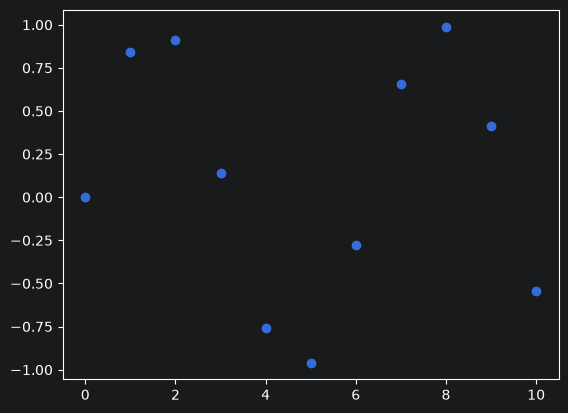

In [3]:
x = np.linspace(0,10,11)
y = np.sin(x)

plt.scatter(x,y)
plt.show()

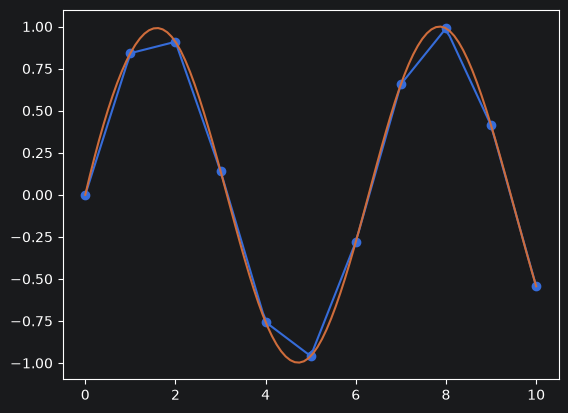

In [4]:
x_new = np.linspace(0,10,100)
for kind in ['linear','cubic']:
    f = interpolate.interp1d(x,y,kind=kind)
    y_new = f(x_new)
    plt.plot(x_new,y_new)

plt.scatter(x,y)
plt.show()
#只能对样本数据点中间的值进行插值

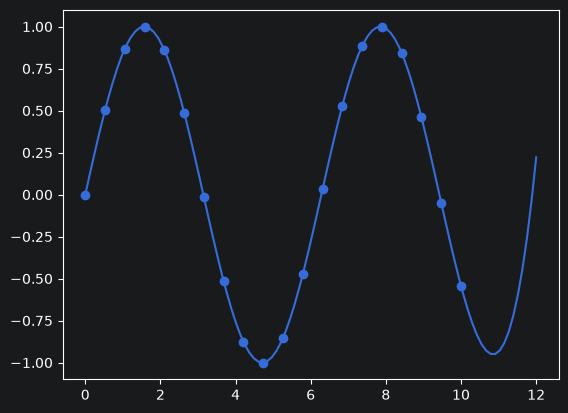

In [5]:
x1 = np.linspace(0,10,20)
y1 = np.sin(x1)
sx1 = np.linspace(0,12,100)
sy1 = interpolate.UnivariateSpline(x1,y1,s = 0)(sx1)
plt.scatter(x1,y1)
plt.plot(sx1,sy1)

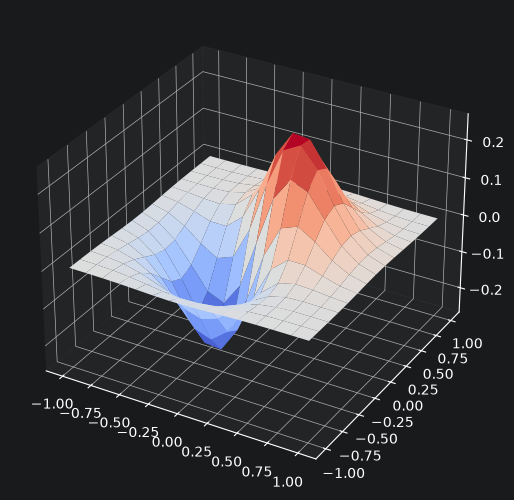

In [6]:
#二次插值
def func(x,y):
    return (x+y)*np.exp(-5.0*(x**2+y**2))

y,x = np.mgrid[-1:1:15j,-1:1:15j]
fvals = func(x,y)

from mpl_toolkits.mplot3d import Axes3D #三维图
from matplotlib import cm
fig = plt.figure()
ax = Axes3D(fig)
fig.add_axes(ax)
ax.plot_surface(x,y,fvals,cmap = cm.coolwarm)
plt.show()

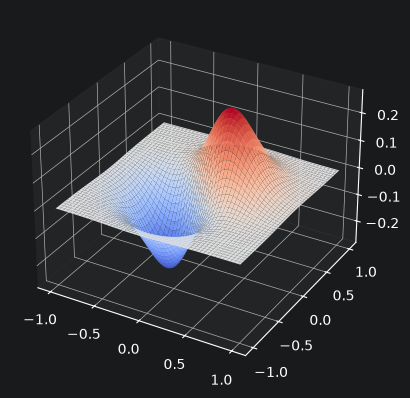

In [11]:
from scipy.interpolate import RectBivariateSpline
newfunc = RectBivariateSpline(y[:, 0], x[0, :], fvals)
xnew = np.linspace(-1,1,100)
ynew = np.linspace(-1,1,100)
fnew = newfunc(xnew,ynew)

X, Y = np.meshgrid(xnew, ynew)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, fnew, cmap=cm.coolwarm)
plt.show()

# 线性代数

In [12]:
from scipy import linalg

In [13]:
#方程组求解
#A*x = b
A = np.array([[1,3,5],[2,5,1],[2,3,8]])
b = np.array([10,8,3])
x = linalg.solve(A,b)
x

array([-9.28,  5.16,  0.76])

In [15]:
A.dot(x)

array([10.,  8.,  3.])

In [16]:
linalg.det(A)

np.float64(-25.000000000000004)

In [17]:
l,v = linalg.eig(A)
print(l,v)

[10.5540456 +0.j -0.5873064 +0.j  4.03326081+0.j] [[-0.51686204 -0.94195144  0.11527992]
 [-0.32845853  0.31778071 -0.81936883]
 [-0.79054957  0.10836468  0.56155611]]


In [24]:
#svd 分解:图像压缩，噪声消除
X = np.array([[0,0,0,2,2],[0,0,0,3,3],[0,0,0,1,1],[1,1,1,0,0],[2,2,2,0,0],[5,5,5,0,0],[1,1,1,0,0]])
U,s,Vh = linalg.svd(X)
np.round(U.dot(U.T)).astype(np.uint8)

array([[1, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0],
       [0, 0, 1, 0, 0, 0, 0],
       [0, 0, 0, 1, 0, 0, 0],
       [0, 0, 0, 0, 1, 0, 0],
       [0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 1]], dtype=uint8)

In [26]:
np.round(Vh.dot(Vh.T)).astype(np.uint8)

array([[1, 0, 0, 0, 0],
       [0, 1, 0, 0, 0],
       [0, 0, 1, 0, 0],
       [0, 0, 0, 1, 0],
       [0, 0, 0, 0, 1]], dtype=uint8)

In [31]:
np.round(np.dot(U[:,:5],np.dot(np.diag(s),Vh))).astype(np.uint8)

array([[0, 0, 0, 2, 2],
       [0, 0, 0, 3, 3],
       [0, 0, 0, 1, 1],
       [1, 1, 1, 0, 0],
       [2, 2, 2, 0, 0],
       [5, 5, 5, 0, 0],
       [1, 1, 1, 0, 0]], dtype=uint8)

# 数值积分

In [32]:
#求一个半圆的面积，半径为1的单位圆：pi*r^2=pi
np.pi/2

1.5707963267948966

In [33]:
def half_circle(x):
    return np.sqrt(1-x**2)

In [38]:
N = 10000
x = np.linspace(-1,1,N)
dx = x[1]-x[0]
y = half_circle(x)
print(np.sum(y*dx))

1.5707946634653687


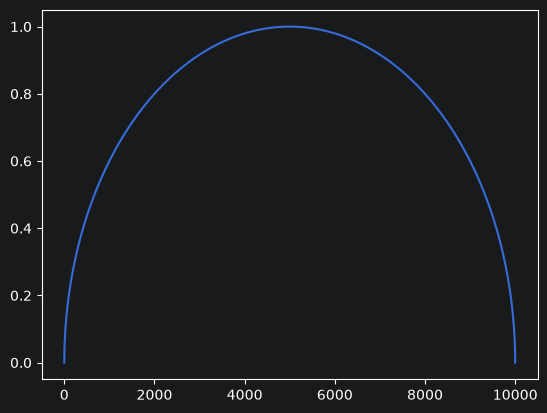

In [42]:
from scipy import integrate
integrate.quad(half_circle,-1,1)
np.trapezoid(y,x)
plt.plot(y)

In [43]:
#二维积分
def half_sphere(x,y):
    return (1-x**2-y**2)**0.5

integrate.dblquad(half_sphere,-1,1,lambda x:-half_circle(x),lambda x:half_circle(x)) #计算二重积分
#integrate.dblquad(
    #被积函数,
    #x的下限, x的上限,
    #y的下限函数,
    #y的上限函数
#)

(2.0943951023931984, 1.0002354500215915e-09)

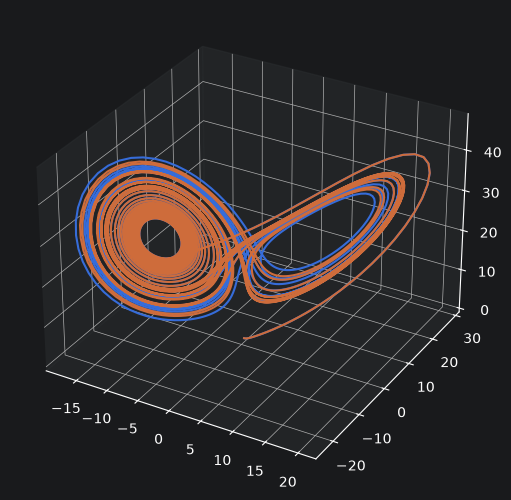

In [53]:
#洛伦兹吸引子:位置对时间的导数：混沌效应，蝴蝶效应
from scipy.integrate import odeint #常微分方程
def lorenz(w,t,p,r,b):
    x,y,z = w
    return p*(y-x),x*(r-z)-y,x*y-b*z
t = np.arange(0,30,0.01)
track1 = odeint(lorenz,(0.0,1.00,0.0),t,args = (10.0,28.0,3.0))
track2 = odeint(lorenz,(0.0,1.01,0.0),t,args = (10.0,28.0,3.0))


from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
fig = plt.figure()
ax = Axes3D(fig)
fig.add_axes(ax)
ax.plot(track1[:,0],track1[:,1],track1[:,2])
ax.plot(track2[:,0],track2[:,1],track2[:,2])
plt.show()

# 信号处理

In [2]:
#设计滤波器，怎么从噪声中，拿到真正的信号
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

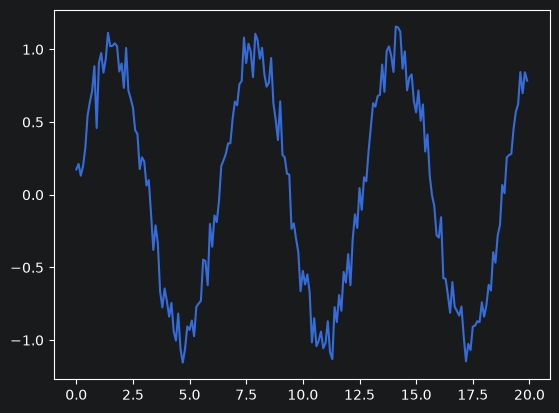

In [3]:
t = np.arange(0,20,0.1)
x = np.sin(t)
noise = np.random.normal(size = x.shape)*0.1
x_n = x+noise

plt.plot(t,x_n)
plt.show()

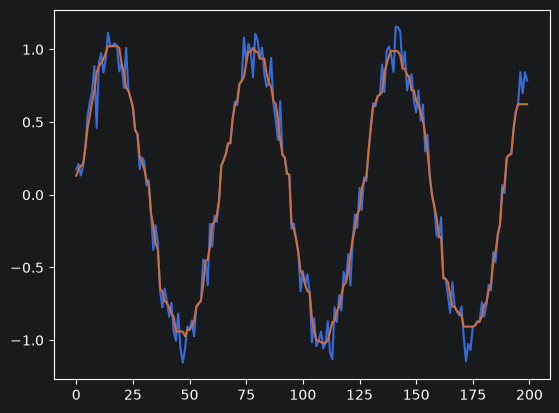

In [4]:
#中值滤波器（帮助信号平滑）
x2 = signal.medfilt(x_n,9)#数值只能是奇数，且数值不能太大  光谱、时间序列，也能处理图像
plt.plot(x_n)
plt.plot(x2)
plt.show()

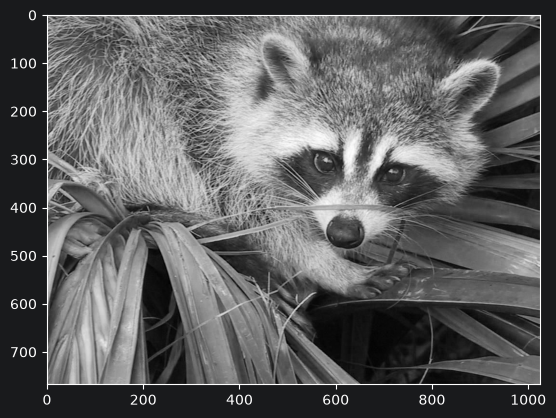

In [9]:
import scipy.datasets

img = scipy.datasets.face()
gray = img[:,:,0]
plt.imshow(gray)
plt.gray()
plt.show()

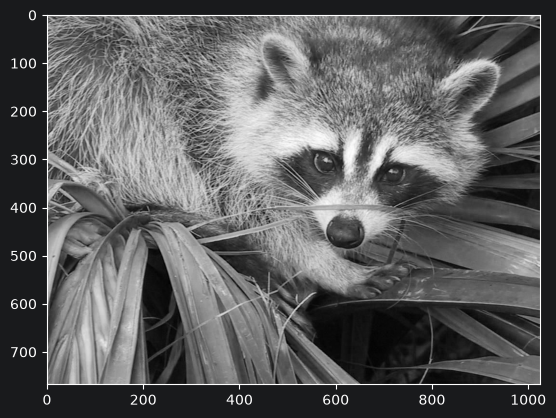

In [14]:
#medfilt() 更通用，medfilt2d() 专门用于二维数据；两者的窗口边长都要求为正奇数。
gray1 = signal.medfilt2d(gray,kernel_size = 1) #kernel_size窗口 越大越平滑
plt.imshow(gray1)
plt.show()

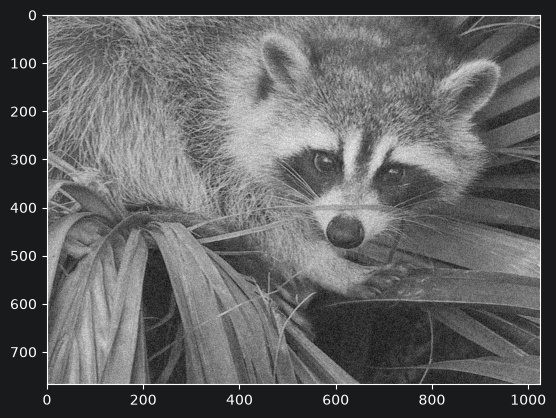

In [16]:
noise = np.random.randint(-50,50,size = gray.shape)
gray_n = gray + noise

plt.imshow(gray_n)
plt.show()

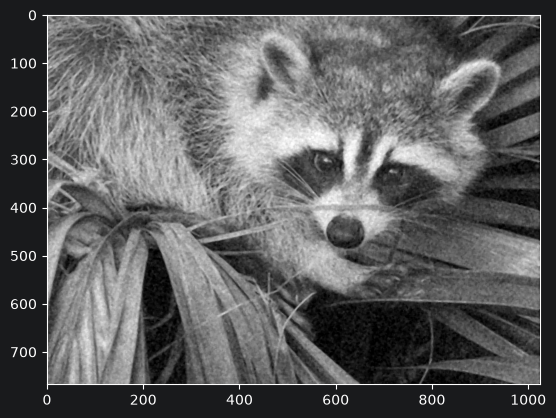

In [23]:
gray_n[gray_n<0]=0
gray_n[gray_n>255]=255
gray_n = gray_n.astype(np.uint8)

gray1 = signal.medfilt2d(gray_n,kernel_size = 5)
plt.imshow(gray1)
plt.show()

# 傅里叶变换

In [24]:
t = np.linspace(0,2*np.pi,50)

In [26]:
s1 = np.sin(t)
s3 = np.sin(3*t)
s5 = np.sin(5*t)
s7 = np.sin(7*t)
s9 = np.sin(9*t)
s11 = np.sin(11*t)
s13 = np.sin(13*t)

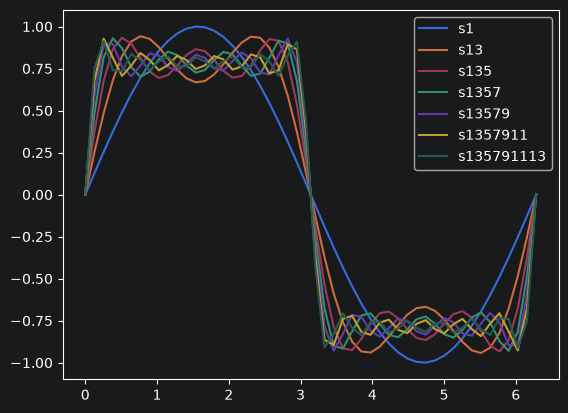

In [30]:
plt.plot(t,s1,label="s1")
plt.plot(t,s1+s3/3,label="s13")
plt.plot(t,s1+s3/3+s5/5,label="s135")
plt.plot(t,s1+s3/3+s5/5+s7/7,label="s1357")
plt.plot(t,s1+s3/3+s5/5+s7/7+s9/9,label="s13579")
plt.plot(t,s1+s3/3+s5/5+s7/7+s9/9+s11/11,label="s1357911")
plt.plot(t,s1+s3/3+s5/5+s7/7+s9/9+s11/11+s13/13,label="s135791113")
plt.legend()
plt.show()

In [31]:
#f(t) = sin(0.5*2*pi*t)+sin(2*2*pi*t)
def signal_sample(t):
    return np.sin(1*np.pi*t)+np.sin(4*np.pi*t)

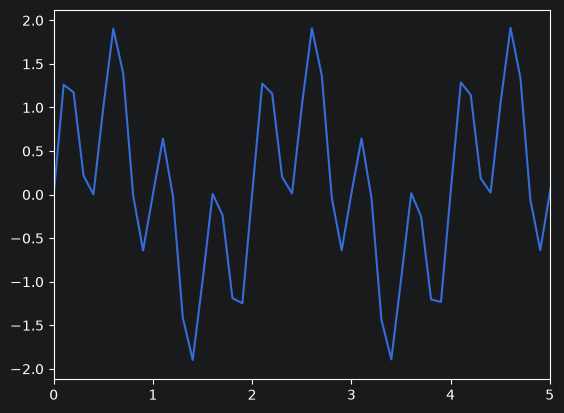

In [33]:
N = 1000
f_s = 10
t =np.linspace(0,N/f_s,N)
f_t = signal_sample(t)
plt.plot(t,f_t)
plt.xlim(0,5)
plt.show()

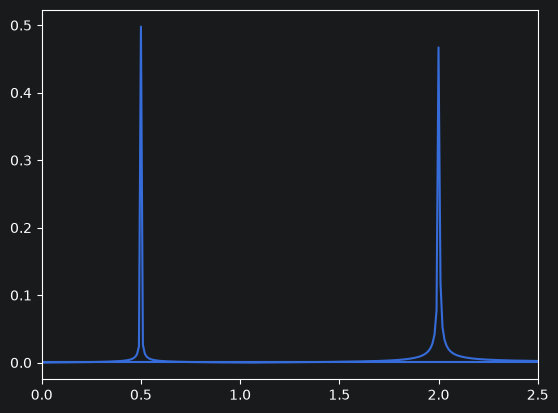

In [41]:
#FFT变换
from scipy import fftpack
F = fftpack.fft(f_t)
f = fftpack.fftfreq(N,1.0/f_s)

plt.plot(f,np.abs(F)/N)
plt.xlim(0,2.5)
plt.show()

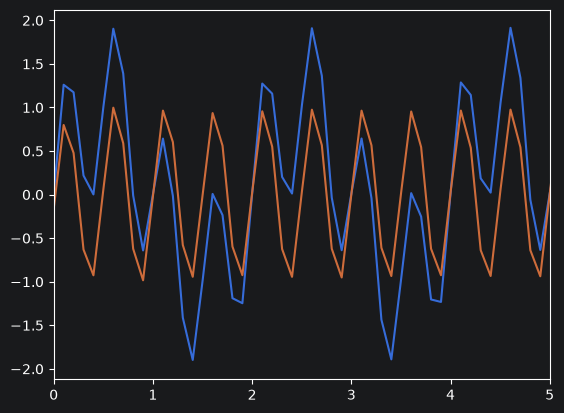

In [49]:
F_filter = F*(abs(f)>1.5)
f_t_filter = fftpack.ifft(F_filter)
plt.plot(t,f_t)
plt.plot(t,f_t_filter.real)
plt.xlim(0,5)
plt.show()